# An epochs is one loop through data
epochs = 100

#0. Loop throught the data
for each in range(epochs):
  #set model to training mode
  model_0.train()

  #1. Forward Pass
  y_pred = model_0(x_train)

  #2. Calculate the loss
  loss = loss_fn(y_pred, y_train)

  #3. Optimizer
  optimizer.zero_grad()

  #4. Perform Backpropagation on the loss with respect to the parameters of the model
  loss.backward()

  #5. step the optimizer (perform gradient descent)
  optimizer.step()

  model_0.eval()
  with torch.inference_mode():
    test_pred = model_0(x_test)
    test_loss = loss_fn(test_pred, y_test)

  print(f" Epoch: {epoch} | Test : {loss} | Test Loss; {test_loss}")

  print(model_0.state_dict())
  print(f"Epoch: {each} | Loss: {loss}")

# An epochs is one loop through data
epochs = 100

#0. Loop throught the data
for each in range(epochs):
  #set model to training mode
  model_0.train()

  #1. Forward Pass
  y_pred = model_0(x_train)

  #2. Calculate the loss
  loss = loss_fn(y_pred, y_train)

  #3. Optimizer
  optimizer.zero_grad()

  #4. Perform Backpropagation on the loss with respect to the parameters of the model
  loss.backward()

  #5. step the optimizer (perform gradient descent)
  optimizer.step()

  model_0.eval()
  with torch.inference_mode():
    test_pred = model_0(x_test)
    test_loss = loss_fn(test_pred, y_test)

  print(f" Epoch: {epoch} | Test : {loss} | Test Loss; {test_loss}")

  print(model_0.state_dict())
  print(f"Epoch: {each} | Loss: {loss}")

In [341]:
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np

torch.__version__

'2.11.0+cpu'

 1. data (preparing and loading)

 Data can be almost anything.. in machine learning.

  * excel spreadsheet
  * image of any kind
  * videos
  * audio like song
  * DNA
  * Text


machine learning is a game of two parts:
1. get data into a numerical representation
2. build a model to learn pattern in that numerical representation



to showcase this we will make linear regression

In [342]:
#creating know data
weight = 0.7
bias = 0.3

#create
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
Y = weight * X + bias
X[:10], Y[:10], len(X), len(Y)

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]),
 50,
 50)

### making the data to traing and test splitting it

In [343]:
train_split = int(0.8 * len(X))
train_split
x_train, y_train = X[:train_split], Y[:train_split]
x_test, y_test = X[train_split:], Y[train_split:]
len(x_train), len(y_train), len(x_test), len(y_test)

(40, 40, 10, 10)

In [344]:
def plot_predictions(train_data=x_train,
                     train_labels=y_train,
                     test_data=x_test,
                     test_labels=y_test,
                     predictions=None):
  """
  plot training data and test data and predictions
  """
  plt.figure(figsize=(10,7))

  plt.scatter(train_data, train_labels, c="b", s=4, label="training data")
  plt.scatter(test_data, test_labels, c="g", s=4, label="testing data")

  if predictions is not None:
    plt.scatter(test_data, predictions, c="r", s=4, label="predictions")

  plt.legend(prop={"size":14});

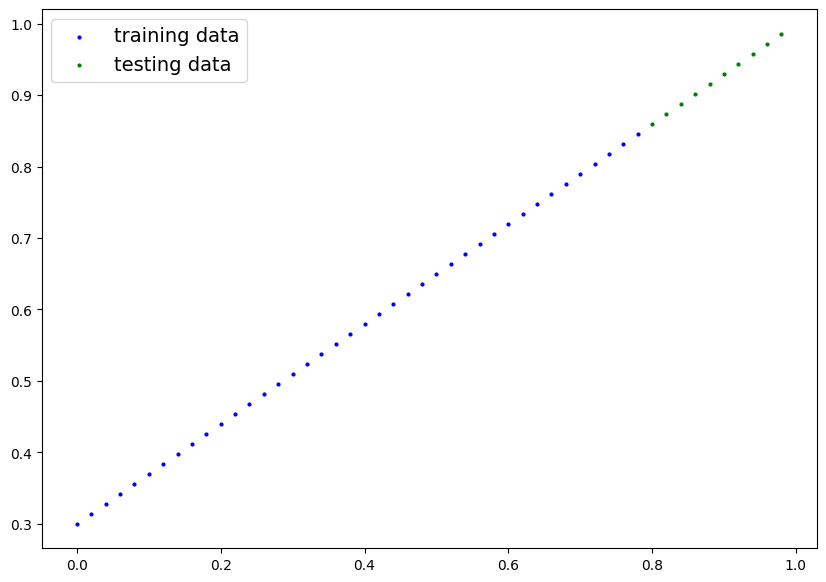

In [345]:
plot_predictions()

## 2. build model
our first pytorch model
this is very exciting.. let's go do it!

because we're going to be building classes throughout the course ,
i'd recommend getting familiar with oop in python

In [346]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.weights = nn.Parameter(torch.rand(1, requires_grad=True, dtype=torch.float32))
        self.bias = nn.Parameter(torch.rand(1, requires_grad=True, dtype=torch.float32))

    def forward(self, x:torch.Tensor) -> torch.Tensor:
      return self.weights * x + self.bias

### pytorch mode buidling essential

* torch.nn - contains all of the building for computational graphs (another word for neural networks)

* torch.nn.parameter - what parameter our model should try and learn, oftern a pytorch layer from torch.nn will set these  for us
* torch.nn.module - the base class for all neural network modules, if you sublass it, you should overwrite forward
* torch.optim = this is where the optimiezers in pytorch live they will help with gradient descent
* def forward () - all nn.module subclasses require you to overwrite forward computation

In [347]:
torch.manual_seed(42)
torch.rand(1)

tensor([0.8823])

In [348]:
#create a random seed
torch.manual_seed(42)

#create an instance of the model (this is a subclass of nn.module)
model_0 = LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.8823], requires_grad=True),
 Parameter containing:
 tensor([0.9150], requires_grad=True)]

In [349]:
#list named parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.8823])), ('bias', tensor([0.9150]))])

###making prediction using 'torch.inference_mode()'

to check our model's prediction power, let's see how well it predicts y_test based on x_test

In [350]:
#make prediction with model
with torch.inference_mode():
   y_preds = model_0(x_test)

#another way of doing this is
# with torch.no_grad():
#   y_preds = model_0(x_test)

y_preds

tensor([[1.6208],
        [1.6385],
        [1.6561],
        [1.6738],
        [1.6914],
        [1.7090],
        [1.7267],
        [1.7443],
        [1.7620],
        [1.7796]])

In [351]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

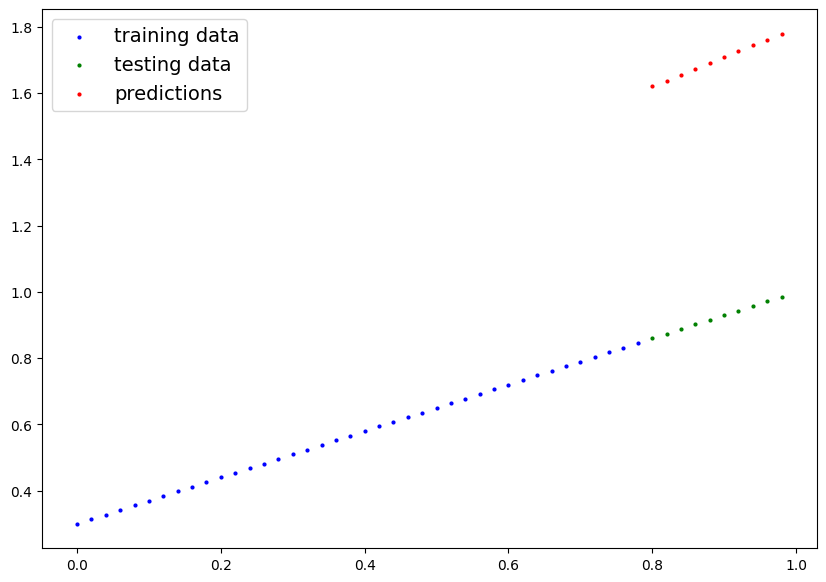

In [352]:
plot_predictions(predictions=y_preds)

## 3. Train Model

the whole idea of training is for a model to moce from some *unknown* parameters to some *known* parameters.

or in other words from a poor representation of the data to a better representation of the data.

one way to measure how poor or how wrong your model predictions are is to use a lose function.

* Note : Loss function may also be called cost function or criterion in different areas. for our case, we're going to refer to it as a loss function.

Things we need to train:

* **Loss Function** : A loss function is to measure how wrong your model's prediction are to the ideal outputs lower is better

* **optimizer** : Take int account the loss of a model and adjust the model's parameter (e.g weight & bias in our case) to improve the loss function.

And specifically for pytorch, we need:

* A training loop
* A testing loop

In [353]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.8823], requires_grad=True),
 Parameter containing:
 tensor([0.9150], requires_grad=True)]

In [354]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.8823])), ('bias', tensor([0.9150]))])

In [355]:
# setup a lose function
loss_fn = nn.L1Loss()

# set an optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01) # learning rate

In [356]:
loss_fn

L1Loss()

In [357]:
optimizer

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

### Building a Training Loop in PYTorch and a Testing Loop

A couple of things we need in a training loop:

1. Loop thorugh the data
2. forward pass (this involves data moving through out model's `forward()` functions )
3. Optimizer Zero grad
4. Loss backword - move background through the network to calculate the gradients of each of the parameters of our model with respect to the loss
5. Optimizer step - use the optimizer to adjust our model's parameters to try and imprve the loss



gradient is change in y and x it's a slope


In [358]:
# An epochs is one loop through data
epochs = 100

epoch_count = []
loss_value = []
test_loss_value = []

#0. Loop throught the data
for epoch in range(epochs):
  #set model to training mode
  model_0.train()

  #1. Forward Pass
  y_pred = model_0(x_train)

  #2. Calculate the loss
  loss = loss_fn(y_pred, y_train)

  #3. Optimizer
  optimizer.zero_grad()

  #4. Perform Backpropagation on the loss with respect to the parameters of the model
  loss.backward()

  #5. step the optimizer (perform gradient descent)
  optimizer.step()

  #Testing
  model_0.eval()
  with torch.inference_mode():
    test_pred = model_0(x_test)
    test_loss = loss_fn(test_pred, y_test)


  if epochs % 10 == 0:
    epoch_count.append(epoch)
    loss_value.append(loss)
    test_loss_value.append(test_loss)
    print(f" Epoch: {epoch} | Test : {loss} | Test Loss; {test_loss}")
    print(model_0.state_dict())

 Epoch: 0 | Test : 0.6860889196395874 | Test Loss; 0.7637526988983154
OrderedDict({'weights': tensor([0.8784]), 'bias': tensor([0.9050])})
 Epoch: 1 | Test : 0.6745679974555969 | Test Loss; 0.7502816915512085
OrderedDict({'weights': tensor([0.8745]), 'bias': tensor([0.8950])})
 Epoch: 2 | Test : 0.6630470156669617 | Test Loss; 0.7368106245994568
OrderedDict({'weights': tensor([0.8706]), 'bias': tensor([0.8850])})
 Epoch: 3 | Test : 0.6515260338783264 | Test Loss; 0.7233396768569946
OrderedDict({'weights': tensor([0.8667]), 'bias': tensor([0.8750])})
 Epoch: 4 | Test : 0.6400049924850464 | Test Loss; 0.7098686695098877
OrderedDict({'weights': tensor([0.8628]), 'bias': tensor([0.8650])})
 Epoch: 5 | Test : 0.6284840703010559 | Test Loss; 0.6963977217674255
OrderedDict({'weights': tensor([0.8589]), 'bias': tensor([0.8550])})
 Epoch: 6 | Test : 0.6169630289077759 | Test Loss; 0.6829267144203186
OrderedDict({'weights': tensor([0.8550]), 'bias': tensor([0.8450])})
 Epoch: 7 | Test : 0.605442

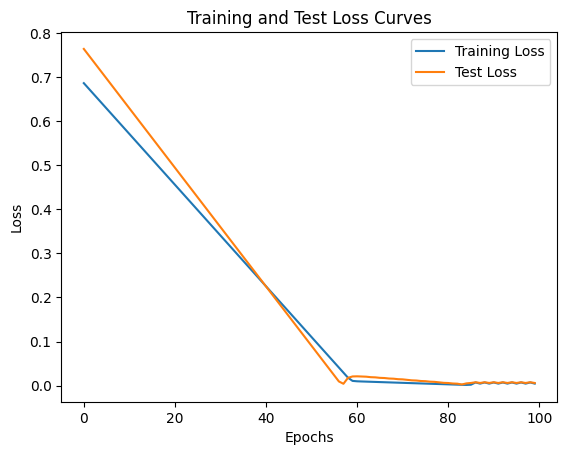

In [359]:
plt.plot(epoch_count, np.array(torch.tensor(loss_value).numpy()), label="Training Loss")
plt.plot(epoch_count, test_loss_value, label="Test Loss")
plt.title("Training and Test Loss Curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

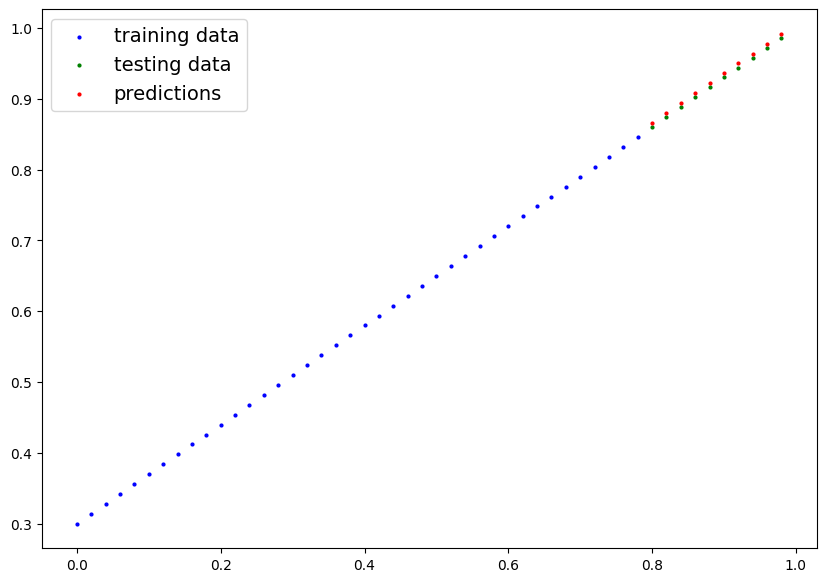

In [360]:
with torch.inference_mode():
  y_preds_new = model_0(x_test)

plot_predictions(predictions=y_preds_new)

In [361]:
weight, bias

(0.7, 0.3)

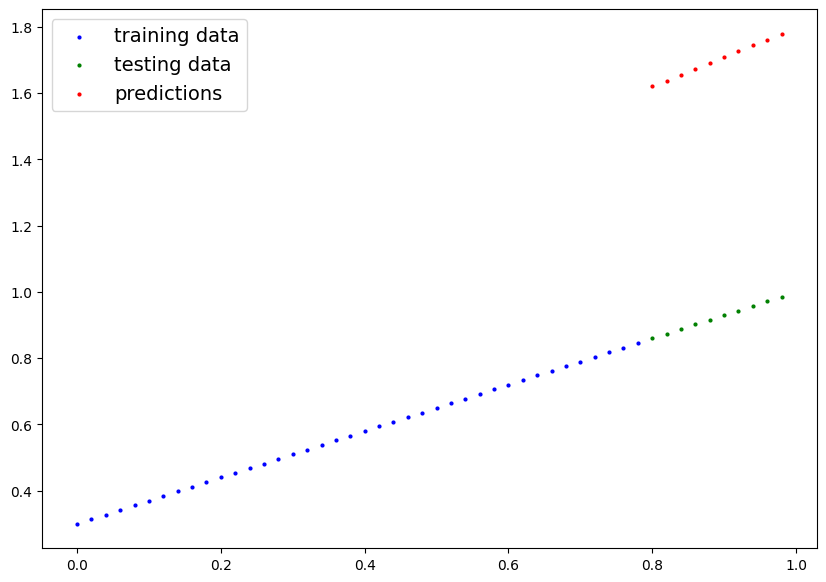

In [362]:
plot_predictions(predictions=y_preds)

**Saving the model**

there are 3 methods for saving and loading models

1. `torch.save()` - allow to save you model in pickle format
2. `torch.load()` - allow to load a saved object
3. `torch.nn.Module.load_state_dict()` - allow you to load a models saved state dict

In [363]:
#saving a pytorch model

from pathlib import Path

#1. Create model directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

#2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

#3. save dict
torch.save(obj=model_0.state_dict(), f=MODEL_SAVE_PATH)

In [364]:
!ls -l models

total 4
-rw-r--r-- 1 root root 2101 Jul 10 10:48 01_pytorch_workflow_model.pth


**Loading a PYtorch model**

since we have our model saved rather the entire model we'll create a new instance of our model class

In [365]:
# to load in a state_dict we have to instantiate a new instance of our model class
loaded_model_0 = LinearRegressionModel()

#load the saved state_dict of model_0
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [366]:
loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.6977])), ('bias', tensor([0.3080]))])

In [367]:
#make some predictions with our loaded models

loaded_model_0.eval()
with torch.inference_mode():
  loaded_model_pred = loaded_model_0(x_test)


loaded_model_pred

tensor([[0.8661],
        [0.8801],
        [0.8940],
        [0.9080],
        [0.9220],
        [0.9359],
        [0.9499],
        [0.9638],
        [0.9778],
        [0.9917]])

In [368]:
model_0.eval()

with torch.inference_mode():
  model_0_pred = model_0(x_test)

model_0_pred

tensor([[0.8661],
        [0.8801],
        [0.8940],
        [0.9080],
        [0.9220],
        [0.9359],
        [0.9499],
        [0.9638],
        [0.9778],
        [0.9917]])

In [369]:
model_0_pred == loaded_model_pred

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## 6. Putting everything together

let's go back through the steps above and see it all in one place

In [370]:
import torch
from torch import nn
import matplotlib.pyplot as plt



# 6.1 data

In [371]:
#create some data formula y = weight + bias

weight = 0.7
bias = 0.3

#create range values

start = 0
end = 1

step = 0.02

#create x and y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1) #without unsqueeze erros will pop up
Y = weight * X + bias

X[:10], Y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [372]:
#split data
train_split = int(0.8 * len(X))
X_train, Y_train = X[:train_split], Y[:train_split]
X_test, Y_test = X[train_split:], Y[train_split:]

len(X_train), len(Y_train), len(X_test), len(Y_test)

(40, 40, 10, 10)

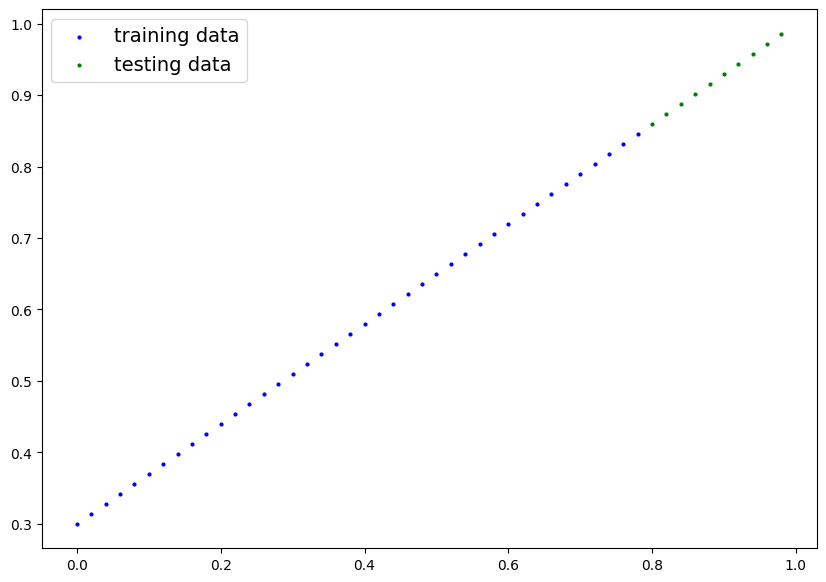

In [373]:
#plot the data
#Note : if you don't have the plot_prediction() function loaded this will throw errors
plot_predictions( X_train, Y_train, X_test, Y_test)

## 6.2 Building a pytorch Linear Model

In [374]:
#creating a linear model
class LinearRegressionModelv2(nn.Module):
  def __init__(self):
    super().__init__()

    #use nn.Linear() for creating the model parameters

    #impletmenting a linear transformer
    self.linear_layer = nn.Linear(in_features=1, out_features=1)


  def forward(self, X) -> torch.Tensor:
    return self.linear_layer(X)



torch.manual_seed(42)
model_1 = LinearRegressionModelv2()
model_1, model_1.state_dict()

(LinearRegressionModelv2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

# 6.3 Training
for training we need :
* Loss function
* Optimizer
* Training Loop
* Testing Loop

In [375]:
#set up the loss functions
loss_fn = nn.L1Loss()

#setup our optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(),lr=0.01 )

In [376]:
#let's write the training loop

torch.manual_seed(42)

epochs = 200

for epoch in range(epochs):

  model_1.train()

  #1. Forward pass
  y_pred_v2 = model_1(X_train)

  #2. Calculate the loss
  loss = loss_fn(y_pred_v2, Y_train)

  #3. optimizer zero grad
  optimizer.zero_grad()

  #4. perform backpropagation
  loss.backward()

  #5. optimizer step
  optimizer.step()


  #testing
  model_1.eval()
  with torch.inference_mode():
    test_pred = model_1(X_test)
    test_loss = loss_fn(test_pred, Y_test)

  #print out what's happening
  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")

Epoch: 0 | Loss: 0.5551779866218567 | Test Loss: 0.5739762187004089
Epoch: 10 | Loss: 0.4399680495262146 | Test Loss: 0.4392663538455963
Epoch: 20 | Loss: 0.3247582018375397 | Test Loss: 0.30455657839775085
Epoch: 30 | Loss: 0.20954827964305878 | Test Loss: 0.16984674334526062
Epoch: 40 | Loss: 0.09433844685554504 | Test Loss: 0.03513689711689949
Epoch: 50 | Loss: 0.023886386305093765 | Test Loss: 0.04784906655550003
Epoch: 60 | Loss: 0.0199567973613739 | Test Loss: 0.04580312222242355
Epoch: 70 | Loss: 0.016517987474799156 | Test Loss: 0.0375305712223053
Epoch: 80 | Loss: 0.013089170679450035 | Test Loss: 0.029944902285933495
Epoch: 90 | Loss: 0.009653178043663502 | Test Loss: 0.02167237363755703
Epoch: 100 | Loss: 0.006215679459273815 | Test Loss: 0.014086711220443249
Epoch: 110 | Loss: 0.002787243574857712 | Test Loss: 0.005814164876937866
Epoch: 120 | Loss: 0.0012645035749301314 | Test Loss: 0.013801807537674904
Epoch: 130 | Loss: 0.0012645035749301314 | Test Loss: 0.01380180753767

In [377]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])

# 6.4 Making and Evaluation

In [378]:
#turn model intro evaluation mode
model_1.eval()

#make predictions
with torch.inference_mode():
  y_preds_v2 = model_1(X_test)

y_preds_v2

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])

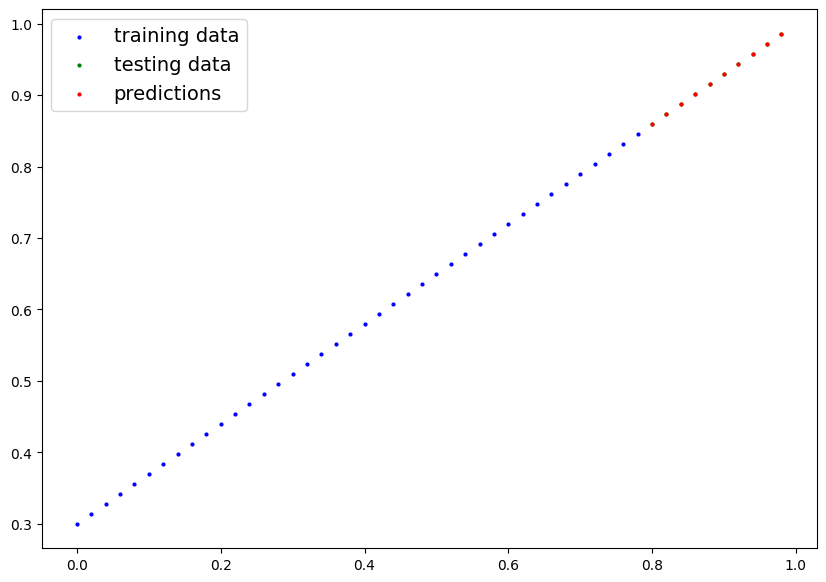

In [379]:
# Check out our model Predictions visually
plot_predictions(predictions=y_preds_v2)

# 6.5 Saving & Loading a Trained Model

In [380]:
from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model_v2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(), f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_v2.pth


In [381]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])

In [384]:
#load a pytorch model
loaded_model_1 = LinearRegressionModelv2()
loaded_model_1.load_state_dict(torch.load(f=MODEL_SAVE_PATH))
loaded_model_1.to(device="cpu")

LinearRegressionModelv2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [385]:
next(loaded_model_1.parameters()).device

device(type='cpu')

In [386]:
loaded_model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])

In [388]:
loaded_model_1.eval()

with torch.inference_mode():
  loaded_model_preds = loaded_model_1(X_test)

loaded_model_preds == y_preds_v2

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])